## The performance of a lock complex
In this notebook, we simulate a lock object on a network. Randomly generated, evenly sized vessels sampled from an exponential distribution have to pass this lock. We add a complex lock object to the graph. Vessels are levelled in the same lock operation if they can fit inside the lock, and register with the lock operator before the start of the lock operation. Based on this behaviour, we will quantify the performance of the lock in terms of efficiency and capacity.

In [1]:
# package(s) used for creating and geo-locating the graph
import networkx as nx
import pyproj
from shapely.geometry import Point, LineString, Polygon
from shapely.ops import transform

# package(s) related to the simulation (creating the vessel, running the simulation)
import datetime
import simpy
import opentnsim

# import of basic core mixins and utils for creating objects, inspecting the output and plotting
from opentnsim.core.logutils import logbook2eventtable
from opentnsim.core.utils import create_object, generate_vessels_from_distribution
from opentnsim.core.visualizations import generate_vessel_gantt_chart

# import of graph
from opentnsim.graph import Graph

# import of simulation
from opentnsim.model import Simulation

# import of modules important for locking
from opentnsim.lock import IsLockChamber, IsLockWaitingArea, IsLockComplex, LockComplexTraversable
from opentnsim.lock.calculations import estimate_lock_capacity, calculate_lock_occupancy
from opentnsim.lock.logutils import calculate_cycle_information, get_vessel_delays

# package(s) needed for inspecting the output
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tqdm

# package(s) needed for running OpenTNSim simulations in parallel
import os
from dask.distributed import Client, LocalCluster
from dask.distributed import as_completed

import logging
# Suppress Dask Distributed INFO messages
logging.getLogger("distributed").setLevel(logging.ERROR)
logging.getLogger("dask").setLevel(logging.ERROR)


print("This notebook is executed with OpenTNSim version {}".format(opentnsim.__version__))

This notebook is executed with OpenTNSim version 2.3.2a2.dev3+g514a752b4.d20260603


#### 0. Create environment

In [2]:
def create_environment(simulation_start = pd.Timestamp('2026-01-01 00:00:00')):
    simulation = Simulation(simulation_start = simulation_start)
    return simulation

#### 1. Create graph
We create a directional graph with a layout similar to that of notebooks 0201, 0202, and 0203. However, we add two additional edges prior to nodes 0 and 1 to show that a lock can also be implemented in a larger graph. These edges are 20km long.

In [3]:
def create_graph_and_add_to_simulation(
    simulation,
    distance_lock_edge = 10000,
):
    graph = Graph()
    graph.add_node(name = '0', geometry = Point(-distance_lock_edge/2,0), epsg = 4087)
    graph.add_node(name = '1', geometry = Point(distance_lock_edge/2,0), epsg = 4087)
    graph.add_edge(('0','1'))
    simulation.add_graph(graph)
    return simulation

#### 1+ Adding infrastructure
We construct the same lock complex as before.

In [4]:
def create_lock_complex_and_add_to_simulation(
    simulation,
    lock_length = 400,
    lock_width = 50,
    lock_depth = 10,
    loop_distance = 500,
):
    env = simulation.env
    lock_chamber = IsLockChamber(
        env=env,
        lock_depth = lock_depth,
        name='Lock',
        gate_open = '0',
        edge = ('0','1'),
        geometry_m = Polygon([
            Point(-lock_length/2, -lock_width/2),
            Point(-lock_length/2, lock_width/2),
            Point(lock_length/2, lock_width/2),
            Point(lock_length/2, -lock_width/2)
        ]),
    )

    edge_length = env.graph.edges[('0','1')]['length_m']
    distance_from_edge_start = edge_length/2-lock_length/2-loop_distance
    
    waiting_area_A = IsLockWaitingArea(
        env=env,
        name = 'Waiting area A',
        edge = ('0','1'),
        orientation = 0,
        distance_from_edge_start = distance_from_edge_start,
    )

    waiting_area_B = IsLockWaitingArea(
        env=env,
        name = 'Waiting area B',
        edge = ('1','0'),
        orientation = 1,
        distance_from_edge_start = distance_from_edge_start,
    )

    lock_complex = IsLockComplex(
        lock_chambers = [lock_chamber],
        waiting_areas = [waiting_area_A, waiting_area_B],
        registration_nodes = ['0','1'],
        env=env,
        name = 'Lock complex',
    )

    return simulation, lock_chamber

#### 2. Create agents
We create the same vessel agent object.

In [5]:
def create_vessels_and_add_to_simulation(
    simulation,
    mean_arrival_rate_up = 30.,
    mean_arrival_rate_down =30.,
    number_of_vessels_up = 10,
    number_of_vessels_down = 10,
    cv_up = 0.5,
    cv_down = 0.5,
):
    env = simulation.env
    Vessel = create_object(
        "Vessel", 
        (
            LockComplexTraversable,     # allows to interact with a lock
        ), 
    )

    def mission(env, vessel):
        """
        Method that defines the mission of the vessel.
        
        In this case: 
            keep moving along the path until its end point is reached
        """
        while True:
            yield from vessel.move()
            
            if vessel.geometry == nx.get_node_attributes(env.graph, "geometry")[vessel.route[-1]]:
                break
    
    upstream_vessels = generate_vessels_from_distribution(
        env=env,
        vessel_class = Vessel,
        vessel_parameters = {'v':4, 'L':100, 'B':20, 'T':5, 'type':'tanker'},
        mean_arrival_rate=mean_arrival_rate_up,
        number_of_vessels=number_of_vessels_up,
        origin = '0',
        destination = '1',    
        seed = 123,
        cv = cv_up,
    )
    
    downstream_vessels = generate_vessels_from_distribution(
        env=env,
        vessel_class = Vessel,
        vessel_parameters = {'v':4, 'L':100, 'B':20, 'T':5, 'type':'tanker'},
        mean_arrival_rate=mean_arrival_rate_down,
        number_of_vessels=number_of_vessels_down,
        origin = '1',
        destination = '0',  
        seed = 456,
        cv = cv_down,
    )
    
    vessels = upstream_vessels + downstream_vessels
    
    for vessel in vessels:
        simulation.add_vessel(vessel, mission)

    return simulation

#### 3. Run simulation
We run the simulation.

In [17]:
def run_simulation(lock_length):
    mean_arrival_rate_up = mean_arrival_rate_down = 40
    nr_vessels_up = nr_vessels_down = 100
    simulation = create_environment()
    simulation = create_graph_and_add_to_simulation(simulation)
    simulation, lock_chamber = create_lock_complex_and_add_to_simulation(simulation, lock_length)
    simulation = create_vessels_and_add_to_simulation(simulation, mean_arrival_rate_up, mean_arrival_rate_down, nr_vessels_up, nr_vessels_down)
    simulation.run()
    
    summary = lock_chamber.get_performance(show=False)

    fig = lock_chamber.plot(
        xlimmin = -6050, 
        xlimmax = 6050,
        ylimmin = pd.Timestamp('2026-01-01 00:00:00'),
        ylimmax = pd.Timestamp('2026-01-01 10:00:00'),
        method='Plotly',
        boundary_nodes = ['0','1']
    )
    
    return summary, fig

In [48]:
cpu_cores = os.cpu_count() or 2
n_workers = max(1, min(cpu_cores - 1, 8))

(16, 8)

In [49]:
cpu_cores = os.cpu_count() or 2
n_workers = max(1, min(cpu_cores - 1, 8))

cluster = LocalCluster(
    n_workers=n_workers,
    threads_per_worker=1,
    processes=True,
    dashboard_address=":8787"
)

client = Client(cluster)
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 8
Total threads: 8,Total memory: 31.28 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:56223,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:56272,Total threads: 1
Dashboard: http://127.0.0.1:56280/status,Memory: 3.91 GiB
Nanny: tcp://127.0.0.1:56226,


In [51]:
lock_length_min = 200
lock_length_max = 600
dL = 25
lock_lengths = np.arange(lock_length_min, lock_length_max + dL, dL)

futures = {
    client.submit(run_simulation, lock_length): lock_length
    for lock_length in lock_lengths
}

summaries = {}
figures = {}

for future in as_completed(futures):
    length = futures[future]
    results = future.result()
    summaries[length] = results[0]
    figures[length] = results[1]

In [52]:
client.close()
cluster.close()

#### 4. Inspect output
We skip the logbooks and inspect the Gantt charts and time-distance diagram.

In [53]:
locking_delays = {}
waiting_to_enter_delays = {}
waiting_for_next_locking_cycle_delays = {}
ic_ratios = {}
for lock_length, summary in summaries.items():
    ic_ratios[lock_length] = summary['Cycle-averaged I/C-ratio']
    locking_delays[lock_length] = ((
        summary['Delay causes']['obstruction (%)'] + summary['Delay causes']['operation of lock (%)']
    )/100)*summary['Average individual vessel delay']
    waiting_to_enter_delays[lock_length] = (summary['Delay causes']['traffic (%)']/100)*summary['Average individual vessel delay']
    waiting_for_next_locking_cycle_delays[lock_length] = (summary['Delay causes']['congestion (%)']/100)*summary['Average individual vessel delay']

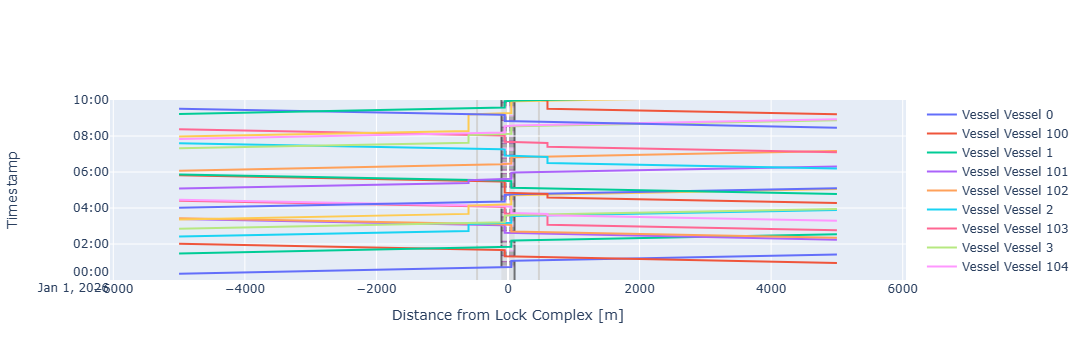

In [54]:
fig = figures[200]
fig

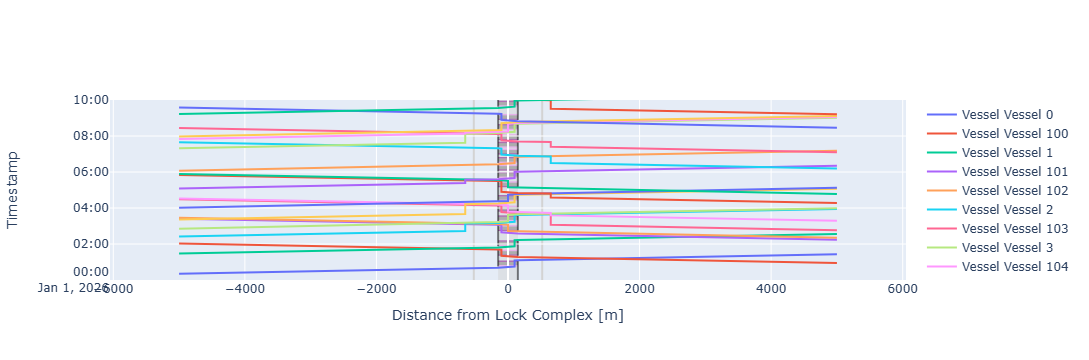

In [55]:
fig = figures[300]
fig

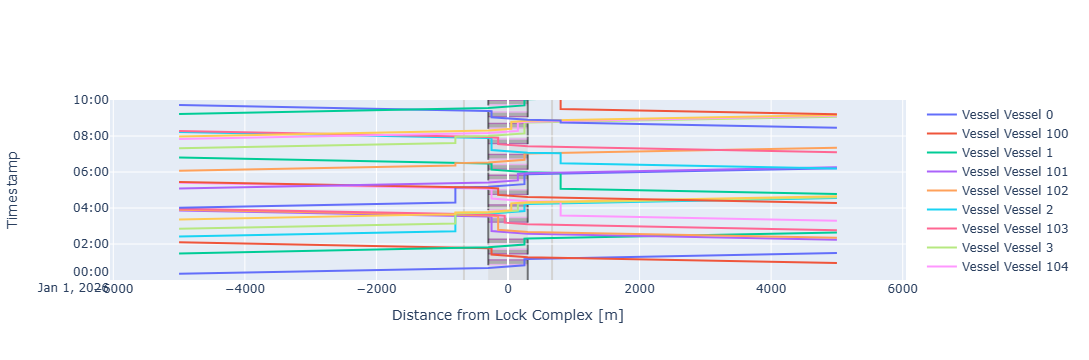

In [56]:
fig = figures[600]
fig

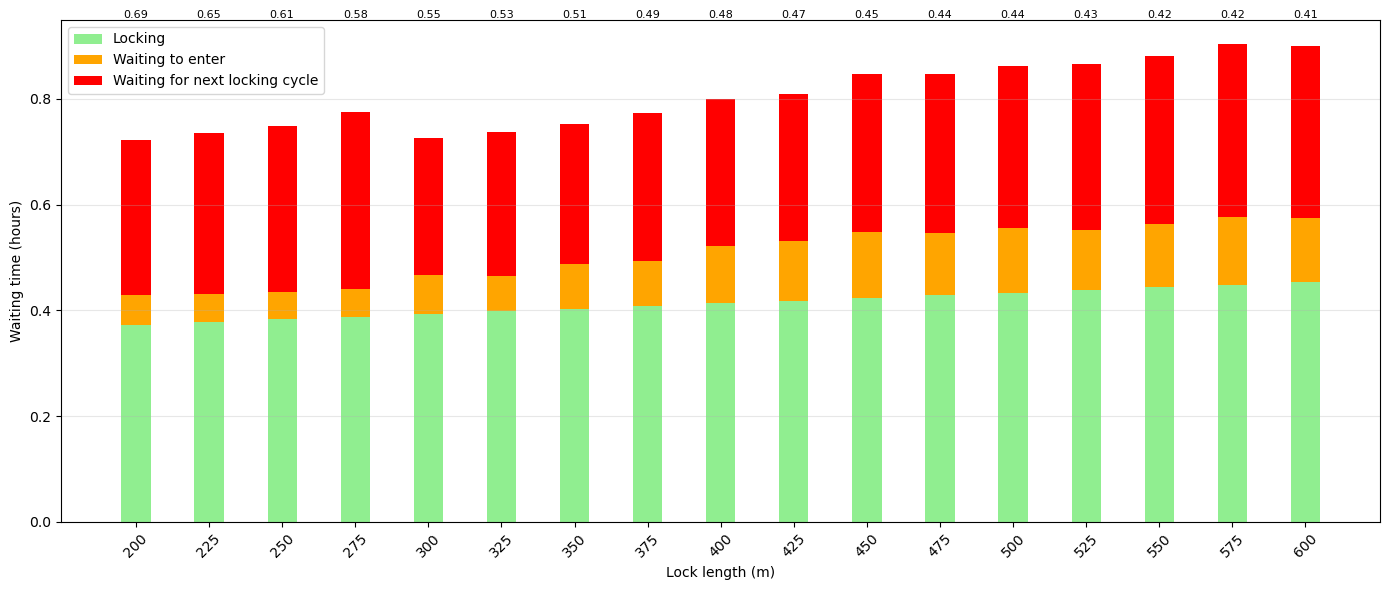

In [61]:
# Extract x values
x = sorted(locking_delays.keys())

# Convert Timedelta to hours
y1 = [locking_delays[k].total_seconds()/3600 for k in x]
y2 = [waiting_to_enter_delays[k].total_seconds()/3600 for k in x]
y3 = [waiting_for_next_locking_cycle_delays[k].total_seconds()/3600 for k in x]

# Create stacked bar plot
fig, ax = plt.subplots(figsize=(14, 6))

ax.bar(x, y1, label='Locking', color='lightgreen', width = 10)
ax.bar(x, y2, bottom=y1, label='Waiting to enter', color='orange', width = 10)
ax.bar(x, y3, bottom=[a+b for a, b in zip(y1, y2)],
       label='Waiting for next locking cycle', color='red', width = 10)
ylims = ax.get_ylim()

for i, ic_ratio in ic_ratios.items():
    ax.text(
        i,
        ylims[-1],  # small offset above bar
        f'{ic_ratio:.2f}',
        ha='center',
        va='bottom',
        fontsize=8
    )

ax.set_xlabel('Lock length (m)')
plt.ylabel('Waiting time (hours)')

plt.xticks(x, rotation=45)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [63]:
from opentnsim.core.utils import inspect_object

In [64]:
Vessel = create_object(
    "Vessel", 
    (
        LockComplexTraversable,     # allows to interact with a lock
    ), 
)

In [65]:
inspect_object(Vessel)

,parameter,class,status
0,name,Identifiable,required
1,v,Movable,required
2,env,SimpyObject,required
3,B,VesselProperties,required
4,L,VesselProperties,required
5,T,VesselProperties,required
6,type,VesselProperties,required
7,route OR origin + destination,Vessel,required (one alternative)
8,id,Identifiable,optional
9,node,Locatable,optional
